# Прогноз из 10:30
Три последовательных недельных окна tuning с расширяющимся train. Каждой неделе предшествуют семь дней val для early stopping. Выбор моделей и калибровки использует прогнозы трёх недель. Последние 14 дат ранее просматривались при разработке. Их локальная оценка получена до финального переобучения.


In [1]:
from pathlib import Path

for p in Path("/kaggle/input").rglob("*"):
    if p.is_file():
        print(p)

/kaggle/input/datasets/sptrent/rwb-hack/test_solo_track.parquet
/kaggle/input/datasets/sptrent/rwb-hack/train_solo_track.parquet


In [2]:
from pathlib import Path
import json
import gc
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
from IPython.display import display
DATA = Path('/kaggle/input/datasets/sptrent/rwb-hack/')
TRAIN_FILE = 'train_solo_track.parquet'
TEST_FILE = 'test_solo_track.parquet'
TRAIN_PATH, TEST_PATH = (DATA / TRAIN_FILE, DATA / TEST_FILE)
if not (TRAIN_PATH.is_file() and TEST_PATH.is_file()) and Path('/kaggle/input').exists():
    train_matches = list(Path('/kaggle/input').rglob(TRAIN_FILE))
    test_matches = list(Path('/kaggle/input').rglob(TEST_FILE))
    if len(train_matches) != 1 or len(test_matches) != 1:
        raise ValueError(f'Укажите TRAIN_PATH и TEST_PATH вручную: train={train_matches}, test={test_matches}')
    TRAIN_PATH, TEST_PATH = (train_matches[0], test_matches[0])
OUT = Path('artifacts/features_1030_windows_v4/features')
MODEL_DIR = OUT.parent / 'models'
IMPORTANCE_DIR = OUT.parent / 'importance'
POSTPROCESS_DIR = OUT.parent / 'postprocessing'
for directory in (OUT, MODEL_DIR, IMPORTANCE_DIR, POSTPROCESS_DIR):
    directory.mkdir(parents=True, exist_ok=True)
TARGET = 'target_1h'
STATUSES = [f'status_{i}' for i in range(1, 7)]
STEP = pd.Timedelta(minutes=30)
TARGET_SCALE = 100000
MAX_TREES = 4000
EARLY_STOPPING_ROUNDS = 150
WINDOW_OFFSETS = tuple(range(-4, 5))
LAG_MAX_LOOKBACK_HOURS = 24
LAG_MIN_PAIRS = 336
LAG_MIN_CORRELATION = 0.05
PERMUTATION_ENABLED = True
PERMUTATION_TOP_N = 10
PERMUTATION_REPEATS = 3
PERMUTATION_MAX_DAYS = 7
FEATURE_PIPELINE_VERSION = '1030_windows_v4'


## Данные и временные границы
Проверяется полная получасовая панель всех маршрутов. Границы задаются до расчёта любых статистик, использующих цель. Словарь корреляционных лагов обучается только до границы train.


In [3]:
history = pd.read_parquet(TRAIN_PATH, columns=['route_id', 'timestamp', TARGET, *STATUSES]).sort_values(['timestamp', 'route_id'])
test = pd.read_parquet(TEST_PATH, columns=['id', 'route_id', 'timestamp'])
times = pd.DatetimeIndex(history.timestamp.unique())
routes = np.sort(history.route_id.unique())
if not (history.notna().all().all() and test.notna().all().all()):
    raise ValueError('В данных есть пропуски')
if not not history.duplicated(['route_id', 'timestamp']).any():
    raise ValueError('Повторяется ключ маршрута и времени')
if not times.equals(pd.date_range(times[0], times[-1], freq=STEP)):
    raise ValueError('Нарушена получасовая сетка')
if not len(history) == len(times) * len(routes):
    raise ValueError('Неполная панель маршрутов')
if not (test.id.is_unique and (not test.duplicated(['route_id', 'timestamp']).any())):
    raise ValueError('Повторы идентификаторов или ключей теста')
end = times[-1]
if not (end.hour, end.minute) == (10, 30):
    raise ValueError('Последняя точка истории должна быть в 10:30')
expected = pd.MultiIndex.from_product([routes, [end + h * STEP for h in range(1, 9)]], names=['route_id', 'timestamp'])
if not expected.difference(pd.MultiIndex.from_frame(test[['route_id', 'timestamp']])).empty:
    raise ValueError('Тест не покрывает все ожидаемые маршруты и горизонты')
if not len(test) == len(expected):
    raise ValueError('Число строк теста отличается от ожидаемого')
values = {name: history[name].to_numpy(dtype=np.float32).reshape(len(times), len(routes)) for name in [TARGET, *STATUSES]}
del history
if not all((np.isfinite(array).all() for array in values.values())):
    raise ValueError('В числовых рядах есть бесконечные значения')
dates = times[(times.hour == 10) & (times.minute == 30) & (times + 8 * STEP <= end)]
if len(dates) <= 28:
    raise ValueError('Недостаточно дат для временного разбиения')
if len(dates) < 63:
    raise ValueError('Недостаточно истории для трёх недель подбора')
holdout_start = dates[-14]
folds = []
for start in (len(dates)-35, len(dates)-28, len(dates)-21):
    folds.append(dict(train=dates[:start-7], val=dates[start-7:start], tuning=dates[start:start+7], test=dates[-14:]))
split_dates = folds[-1]
tune_start = split_dates['tuning'][0]
LAG_VALIDATION_FIT_BEFORE = split_dates['val'][0].normalize()
display(pd.DataFrame([dict(fold=i+1, period=k, first=v[0], last=v[-1], days=len(v)) for i,f in enumerate(folds) for k,v in f.items()]))


,fold,period,first,last,days
0,1,train,2025-07-28 10:30:00,2025-09-19 10:30:00,54
1,1,val,2025-09-20 10:30:00,2025-09-26 10:30:00,7
2,1,tuning,2025-09-27 10:30:00,2025-10-03 10:30:00,7
3,1,test,2025-10-18 10:30:00,2025-10-31 10:30:00,14
4,2,train,2025-07-28 10:30:00,2025-09-26 10:30:00,61
5,2,val,2025-09-27 10:30:00,2025-10-03 10:30:00,7
6,2,tuning,2025-10-04 10:30:00,2025-10-10 10:30:00,7
7,2,test,2025-10-18 10:30:00,2025-10-31 10:30:00,14
8,3,train,2025-07-28 10:30:00,2025-10-03 10:30:00,68
9,3,val,2025-10-04 10:30:00,2025-10-10 10:30:00,7


## Исторические признаки и окна
Используются исходные признаки: уровни цели и статусов, средние за 2/6 часов, изменения за час, статусные суммы и отношения, суточные лаги, отклонение от среднего и отношение текущего уровня к предыдущим дням.

Вокруг каждого лага строится окно ±4 получасовых шага. Для последних значений и сглаженных сигналов доступны только точки не позже собственного старта: положительные сдвиги не создаются. Одинаковые источники не дублируются: например, соседние окна target_back_0/1/2/4 объединяются в target_back_0…8. Для status_latest добавляются back_1…4. Лаги сутки/двое назад и сезонные слоты получают все девять соседей. Исходные центральные признаки сохранены. Эквивалентные change_1h статусов 4-6 заменены на diff_hourly.

Суммы статусов не являются числом уникальных товаров. Названия warehouse_total_load, hub_buffer и hub_gate_bottleneck обозначают формулы, а не подтверждённые физические показатели. Недоступная история остаётся NaN.

Для цели и каждого статуса рассчитываются общая сумма по всем маршрутам в доступный момент и её изменение за час. Соседние исторические значения используют только левую часть окна у старта.


In [4]:
import pyarrow as pa
import pyarrow.parquet as pq
target = values[TARGET]

def past(array, positions):
    positions = np.asarray(positions, dtype=np.int64)
    valid = (positions >= 0) & (positions < len(array))
    result = array[np.clip(positions, 0, len(array) - 1)].astype(np.float32)
    result[~valid] = np.nan
    return result

def average_available(matrices):
    total = np.zeros_like(matrices[0], dtype=np.float32)
    count = np.zeros_like(total)
    for matrix in matrices:
        valid = np.isfinite(matrix)
        total += np.where(valid, matrix, 0)
        count += valid
    return np.divide(total, count, out=np.full_like(total, np.nan), where=count > 0)

def rolling(array, steps):
    return pd.DataFrame(array).rolling(steps, min_periods=1).mean().to_numpy(dtype=np.float32)
means = {(name, steps): rolling(array, steps) for name, array in values.items() for steps in (4, 12)}
level24 = rolling(target, 48)
positions = np.arange(len(times))
extra_signals = {}
for name in STATUSES[:3]:
    extra_signals[name + '_hourly'] = values[name] + past(values[name], positions - 1)
extra_signals['warehouse_total_load'] = sum((extra_signals[name + '_hourly'] for name in STATUSES[:3]))
extra_signals['warehouse_processing_rate'] = extra_signals['status_3_hourly'] / (extra_signals['status_1_hourly'] + np.float32(1e-05))
for name in STATUSES[3:]:
    extra_signals[name + '_diff_hourly'] = values[name] - past(values[name], positions - 2)
extra_signals['hub_buffer'] = values['status_5'] - values['status_4']
extra_signals['hub_gate_bottleneck'] = extra_signals['status_4_diff_hourly'] - extra_signals['status_6_diff_hourly']
extra_signals['target_acceleration'] = past(target, positions - 1) - past(target, positions - 2)
hub_signal = extra_signals['status_6_diff_hourly']
extra_signals['target_vs_mean_6h'] = target - means[TARGET, 12]
recent = means[TARGET, 4]
usual = average_available([past(recent, positions - day * 48) for day in range(1, 8)])
extra_signals['morning_level_ratio'] = np.divide(recent, usual, out=np.full_like(recent, np.nan), where=usual > 0)

def offset_name(base, offset):
    if offset == 0:
        return base
    return f"{base}_offset_{('m' if offset < 0 else 'p')}{abs(offset)}"

def add_window(common, base, array, anchor, offsets=WINDOW_OFFSETS):
    for offset in offsets:
        common[offset_name(base, offset)] = past(array, anchor + offset)

def common_features(origins):
    common = {}
    local_target_lags = sorted({k - offset for k in (0, 1, 2, 4) for offset in WINDOW_OFFSETS if k - offset >= 0})
    for lag in local_target_lags:
        common[f'target_back_{lag}'] = past(target, origins - lag)
    causal_offsets = tuple((offset for offset in WINDOW_OFFSETS if offset <= 0))
    for name, array in values.items():
        for steps in (4, 12):
            add_window(common, f'{name}_mean_{steps}', means[name, steps], origins, causal_offsets)
        if name in STATUSES:
            common[f'{name}_latest'] = array[origins]
            for lag in range(1, 5):
                common[f'{name}_back_{lag}'] = past(array, origins - lag)
            if name in STATUSES[:3]:
                change = array - past(array, positions - 2)
                add_window(common, f'{name}_change_1h', change, origins, causal_offsets)
    for name, array in extra_signals.items():
        add_window(common, name, array, origins, causal_offsets)
    for lag in (48, 96):
        add_window(common, f'target_1h_lag_{lag}', target, origins - lag)
    add_window(common, 'warehouse_total_load_lag_48', extra_signals['warehouse_total_load'], origins - 48)
    add_window(common, 'status_6_diff_hourly_lag_48', hub_signal, origins - 48)
    return common
CORRELATION_COLUMNS = ['selected_status6_lag_steps', 'selected_status6_correlation', 'selected_status6_pair_count', 'status6_lag_valid', 'lagged_status6_signal', 'lagged_status6_signal_available']

for name, series in values.items():
    network = series.sum(axis=1, dtype=np.float64).astype(np.float32)[:, None]
    for suffix, signal in [('latest', network), ('change_1h', network - past(network, positions-2))]:
        extra_signals[f'network_{name}_{suffix}'] = np.broadcast_to(signal, target.shape)


## Корреляционный лаг маршрута
На полной получасовой истории train ищется максимальная положительная Pearson-корреляция target(u) с diff_status6(u−L), L=2…48 шагов. Минимум 336 пар и корреляция >0,05 - эвристики, не тест значимости.

Выбранный L фиксирован для маршрута. Для горизонта h нужен сигнал origin+h−L. Помимо центра добавляются соседи ±2 часа, каждый доступен только при собственном источнике ≤origin. У каждого соседа есть флаг доступности. При слабой связи лаг и сигнал NaN. Для финального refit словарь пересчитывается на всей истории; оценочные parquet и модели сохраняются отдельно.

Для выбора лага и его применения из цели и изменения статуса 6 вычитается среднее того же получаса за предыдущие семь суток. Для каждого окна словарь строится заново до начала val.
Исходный лаг статуса 6 и лаг по остаткам сохраняются отдельными группами.


In [5]:
def calculate_dynamic_shoulder(target_values, status6_diff, timestamps, route_ids, *, fit_before, max_lookback_hours=24, min_pairs=336, min_correlation=0.05, route_block_size=128):
    grid = pd.DatetimeIndex(timestamps)
    route_ids = np.asarray(route_ids)
    target_values, status6_diff = (np.asarray(target_values), np.asarray(status6_diff))
    if target_values.shape != status6_diff.shape or target_values.shape != (len(grid), len(route_ids)):
        raise ValueError('Ожидаются два массива [время, маршрут] одной формы')
    if len(grid) == 0 or not grid.equals(pd.date_range(grid[0], periods=len(grid), freq=STEP)):
        raise ValueError('Для выбора лага нужна упорядоченная получасовая сетка без дубликатов')
    if len(np.unique(route_ids)) != len(route_ids):
        raise ValueError('Идентификаторы маршрутов повторяются')
    steps = float(max_lookback_hours) * 2
    if not np.isfinite(steps) or steps < 2 or (not steps.is_integer()):
        raise ValueError('Граница поиска должна задавать целое число получасов, не меньше двух')
    if not isinstance(min_pairs, (int, np.integer)) or min_pairs < 3:
        raise ValueError('min_pairs должен быть целым числом >=3')
    if not 0 <= min_correlation <= 1 or route_block_size < 1:
        raise ValueError('Некорректные параметры выбора корреляции')
    max_lag = int(steps)
    stop = int(grid.searchsorted(pd.Timestamp(fit_before), side='left'))
    anchors = np.arange(max_lag + 2, stop)
    best_corr = np.full(len(route_ids), np.nan)
    best_lag = np.full(len(route_ids), np.nan)
    best_pairs = np.zeros(len(route_ids), dtype=np.int32)
    for start in range(0, len(route_ids), route_block_size):
        finish = min(start + route_block_size, len(route_ids))
        x = target_values[anchors, start:finish].astype(np.float64)
        for lag in range(2, max_lag + 1):
            z = status6_diff[anchors - lag, start:finish].astype(np.float64)
            valid = np.isfinite(x) & np.isfinite(z)
            count = valid.sum(axis=0)
            xx, zz = (np.where(valid, x, 0), np.where(valid, z, 0))
            divisor = np.maximum(count, 1)
            sx, sz = (xx.sum(axis=0), zz.sum(axis=0))
            covariance = (xx * zz).sum(axis=0) - sx * sz / divisor
            vx = np.maximum((xx * xx).sum(axis=0) - sx * sx / divisor, 0)
            vz = np.maximum((zz * zz).sum(axis=0) - sz * sz / divisor, 0)
            denominator = np.sqrt(vx * vz)
            corr = np.divide(covariance, denominator, out=np.full(finish - start, np.nan), where=(count >= min_pairs) & (denominator > 0))
            corr = np.clip(corr, -1, 1)
            previous = best_corr[start:finish]
            better = np.isfinite(corr) & (~np.isfinite(previous) | (corr > previous))
            best_corr[start:finish][better] = corr[better]
            best_lag[start:finish][better] = lag
            best_pairs[start:finish][better] = count[better]
    accepted = np.isfinite(best_corr) & (best_corr > min_correlation)
    return pd.DataFrame({'route_id': route_ids, 'selected_status6_lag_steps': np.where(accepted, best_lag, np.nan), 'selected_status6_correlation': best_corr, 'selected_status6_pair_count': best_pairs, 'status6_lag_valid': accepted.astype(np.int8)})

def correlation_block(frame, h, lag_table, signal_array, prefix, chunk_rows=200000):
    if h not in range(1, 9) or chunk_rows < 1:
        raise ValueError('Некорректный горизонт или размер блока')
    by_route = lag_table.set_index('route_id').reindex(routes)
    route_index = pd.Index(routes)
    lag = by_route.selected_status6_lag_steps.to_numpy(dtype=np.float32)
    extra_columns = [offset_name(base, offset) for offset in WINDOW_OFFSETS if offset != 0 for base in ('lagged_status6_signal', 'lagged_status6_signal_available')]
    names = CORRELATION_COLUMNS + extra_columns
    result = np.full((len(frame), len(names)), np.nan, dtype=np.float32)
    for start in range(0, len(frame), chunk_rows):
        finish = min(start + chunk_rows, len(frame))
        block = frame.iloc[start:finish]
        origin = times.get_indexer(pd.DatetimeIndex(block.cutoff))
        route = route_index.get_indexer(block.route_id)
        if (origin < 0).any() or (route < 0).any():
            raise ValueError('Строка не сопоставлена с историей')
        selected = lag[route]
        for j, name in enumerate(CORRELATION_COLUMNS[:4]):
            result[start:finish, j] = by_route[name].to_numpy(dtype=np.float32)[route]
        for offset in WINDOW_OFFSETS:
            source = origin + h - np.nan_to_num(selected, nan=0).astype(np.int64) + offset
            available = np.isfinite(selected) & (source >= 0) & (source <= origin) & (source < len(times))
            signal = signal_array[np.clip(source, 0, len(times) - 1), route].astype(np.float32)
            available &= np.isfinite(signal)
            result[start:finish, names.index(offset_name('lagged_status6_signal', offset))] = np.where(available, signal, np.nan)
            result[start:finish, names.index(offset_name('lagged_status6_signal_available', offset))] = available.astype(np.float32)
    names = [prefix + name for name in names]
    frame = frame.drop(columns=names, errors='ignore')
    return pd.concat([frame, pd.DataFrame(result, columns=names, index=frame.index)], axis=1)
def remove_seasonality(series):
    typical = average_available([past(series, positions - 48*d) for d in range(1,8)])
    return series - typical

residual_target = remove_seasonality(target)
residual_signal = remove_seasonality(hub_signal)

def fit_lags(boundary):
    tables = []
    for y, signal, prefix in ((target,hub_signal,''),(residual_target,residual_signal,'residual_')):
        table = calculate_dynamic_shoulder(y,signal,times,routes,fit_before=boundary,max_lookback_hours=LAG_MAX_LOOKBACK_HOURS,min_pairs=LAG_MIN_PAIRS,min_correlation=LAG_MIN_CORRELATION)
        tables.append(table.rename(columns={c:prefix+c for c in table.columns if c != 'route_id'}))
    return tables[0].merge(tables[1],on='route_id',validate='one_to_one')

def add_correlation_features(frame,h,lag_table):
    frame = correlation_block(frame,h,lag_table,hub_signal,'')
    residual_table = lag_table[['route_id',*['residual_'+c for c in CORRELATION_COLUMNS[:4]]]].copy()
    residual_table.columns = ['route_id',*CORRELATION_COLUMNS[:4]]
    return correlation_block(frame,h,residual_table,residual_signal,'residual_')

validation_lag_table = fit_lags(LAG_VALIDATION_FIT_BEFORE)
validation_lag_table.to_csv(OUT.parent / 'status6_lags_validation.csv', index=False)


## Матрицы восьми горизонтов
Каждая историческая строка - маршрут и старт в 10:30 с известной меткой данного горизонта. Сезонные значения берутся относительно прогнозируемого слота, включая ±2 часа. Средние slot_daily7/slot_weekly4 получают отдельное значение для каждого сдвига, а не усреднение внутри окна. Центральные profile28 и overlap используются только постобработкой. Календарь относится к будущему слоту.

Для профилей slot_daily7 и slot_weekly4 вычисляются сдвиг пика в минутах, размах и разность средних правой и левой частей окна. При нескольких равных максимумах используется их средняя позиция. Для календаря остаются день недели, выходной и циклические координаты дня недели.


In [6]:
def horizon_dataset(h, origins):
    slot = origins + h
    dates = times[origins] + h * STEP
    common = common_features(origins)
    frame = pd.DataFrame({'cutoff': times[origins].repeat(len(routes)), 'timestamp': dates.repeat(len(routes)), 'route_id': np.tile(routes, len(origins)), **{name: matrix.ravel() for name, matrix in common.items()}})
    calendar = dict(dayofweek=dates.dayofweek, is_weekend=(dates.dayofweek >= 5).astype(np.int8))
    calendar['weekday_sin'] = np.sin(2 * np.pi * dates.dayofweek / 7)
    calendar['weekday_cos'] = np.cos(2 * np.pi * dates.dayofweek / 7)
    for name, array in calendar.items():
        frame[name] = np.repeat(array, len(routes))
    frame = add_correlation_features(frame, h, validation_lag_table)
    seasonal_columns = {}
    for offset in WINDOW_OFFSETS:
        for day in (1, 2, 7):
            seasonal_columns[offset_name(f'slot_days_back_{day}', offset)] = past(target, slot - day * 48 + offset).ravel()
        for name, days in [('slot_daily7', range(1, 8)), ('slot_weekly4', (7, 14, 21, 28))]:
            seasonal_columns[offset_name(name, offset)] = average_available([past(target, slot - day * 48 + offset) for day in days]).ravel()
    for base in ('slot_daily7','slot_weekly4'):
        window = np.column_stack([seasonal_columns[offset_name(base,k)] for k in WINDOW_OFFSETS])
        valid = np.isfinite(window)
        maximum = np.where(valid, window, -np.inf).max(axis=1)
        minimum = np.where(valid, window, np.inf).min(axis=1)
        peak = valid & (window == maximum[:,None])
        count = peak.sum(axis=1)
        shift = np.divide(peak @ np.asarray(WINDOW_OFFSETS, dtype=float), count, out=np.full(len(window),np.nan), where=count>0)
        seasonal_columns[base+'_peak_minutes'] = shift * 30
        seasonal_columns[base+'_range'] = np.where(count>0, maximum-minimum, np.nan)
        seasonal_columns[base+'_right_minus_left'] = window[:,5:].mean(axis=1)-window[:,:4].mean(axis=1)
    frame = pd.concat([frame, pd.DataFrame(seasonal_columns, index=frame.index)], axis=1)
    profile = np.zeros((len(origins), len(routes)))
    counts = np.zeros_like(profile)
    for day in range(1, 29):
        level = past(level24, origins - day * 48)
        adjusted = past(target, slot - day * 48) * level24[origins] / np.maximum(level, 1)
        profile += np.nan_to_num(adjusted)
        counts += np.isfinite(adjusted)
    frame['profile28'] = np.divide(profile, counts, out=np.full_like(profile, np.nan), where=counts > 0).ravel()
    if h == 1:
        lower = np.zeros_like(target[origins])
        upper = past(target, origins - 2)
        for position in (origins - 1, origins):
            total = past(target, position)
            lower, upper = (np.maximum(0, total - upper), np.minimum(total, total - lower))
        seasonal = frame[['slot_daily7', 'slot_weekly4']].mean(axis=1).to_numpy()
        frame['overlap'] = np.where((lower <= upper).ravel(), (lower + upper).ravel() / 2 + seasonal / 2, seasonal)
    else:
        frame['overlap'] = np.nan
    raw_target_sources = []
    for lag in range(9):
        raw_target_sources.append((f'target_back_{lag}', -lag, lag in (0, 1, 2, 4)))
    for lag in (48, 96):
        for offset in WINDOW_OFFSETS:
            raw_target_sources.append((offset_name(f'target_1h_lag_{lag}', offset), -lag + offset, offset == 0))
    for day in (1, 2, 7):
        for offset in WINDOW_OFFSETS:
            raw_target_sources.append((offset_name(f'slot_days_back_{day}', offset), h - day * 48 + offset, offset == 0))
    seen, redundant = (set(), [])
    for name, source, central in sorted(raw_target_sources, key=lambda item: not item[2]):
        if source in seen:
            redundant.append(name)
        else:
            seen.add(source)
    frame = frame.drop(columns=redundant)
    numeric = frame.columns.difference(['cutoff', 'timestamp', 'route_id'])
    return frame.astype({name: 'float32' for name in numeric}).copy()

def write_horizon(h):
    available_origins = np.flatnonzero((times.hour == 10) & (times.minute == 30) & (np.arange(len(times)) + h < len(times)))
    path = OUT / f'history_h{h}.parquet'
    frame = horizon_dataset(h, available_origins)
    frame['y'] = target[available_origins + h].ravel()
    if not frame.columns.is_unique or not ((frame.cutoff.dt.hour == 10) & (frame.cutoff.dt.minute == 30)).all():
        raise ValueError('Нарушена схема признаков или время старта')
    frame.to_parquet(path, index=False, compression='zstd')
    features = horizon_dataset(h, np.array([len(times) - 1]))
    requests = test.loc[test.timestamp.eq(end + h * STEP)]
    future = requests.merge(features, on=['route_id', 'timestamp'], how='left', validate='one_to_one')
    if not future.cutoff.eq(end).all() or not future.id.equals(requests.id.reset_index(drop=True)):
        raise ValueError('Ошибка сопоставления тестовых строк')
    future.to_parquet(OUT / f'submission_h{h}.parquet', index=False)
    print(f'h={h}: история {len(frame):,}, submission {len(future):,}, модельных признаков {len(frame.columns) - 6}')
for h in range(1, 9):
    write_horizon(h)
feature_names = list(dict.fromkeys((name for h in range(1, 9) for name in pq.read_schema(OUT / f'history_h{h}.parquet').names)))
FEATURE_GROUPS = {'calendar': ['dayofweek', 'is_weekend', 'weekday_sin', 'weekday_cos'], 'local_statuses': [name for name in feature_names if any((name.startswith(prefix) for prefix in ('status_1_hourly', 'status_2_hourly', 'status_3_hourly', 'warehouse_total_load', 'warehouse_processing_rate'))) and 'lag_48' not in name], 'hub_combinations': [name for name in feature_names if any((name.startswith(prefix) for prefix in ('status_4_diff_hourly', 'status_5_diff_hourly', 'status_6_diff_hourly', 'hub_buffer', 'hub_gate_bottleneck'))) and 'lag_48' not in name], 'historical_lags': [name for name in feature_names if 'lag_48' in name or 'lag_96' in name], 'target_change': [name for name in feature_names if name.startswith('target_acceleration')], 'correlation_lag': [name for name in feature_names if name in CORRELATION_COLUMNS or name.startswith('lagged_status6_signal')], 'seasonal_windows': [name for name in feature_names if name.startswith('slot_')], 'recent_target': [name for name in feature_names if name.startswith('target_back_')], 'recent_statuses': [name for name in feature_names if any((name.startswith(f'status_{i}_back_') or name == f'status_{i}_latest' for i in range(1, 7)))]}

del values, means, level24, extra_signals, positions, recent, usual
FEATURE_GROUPS['network'] = [name for name in feature_names if name.startswith('network_')]
FEATURE_GROUPS['residual_correlation_lag'] = [name for name in feature_names if name.startswith('residual_')]
(OUT.parent / 'feature_pipeline.json').write_text(json.dumps({'version': FEATURE_PIPELINE_VERSION, 'window_offsets_steps': list(WINDOW_OFFSETS), 'training_origin': '10:30', 'validation_lag_fit_before': str(LAG_VALIDATION_FIT_BEFORE), 'splits': {key: [str(period.min()), str(period.max())] for key, period in split_dates.items()}, 'feature_groups': FEATURE_GROUPS}, ensure_ascii=False, indent=2))


h=1: история 96,000, submission 1,000, модельных признаков 378
h=2: история 96,000, submission 1,000, модельных признаков 380
h=3: история 96,000, submission 1,000, модельных признаков 382
h=4: история 96,000, submission 1,000, модельных признаков 384
h=5: история 96,000, submission 1,000, модельных признаков 386
h=6: история 96,000, submission 1,000, модельных признаков 388
h=7: история 96,000, submission 1,000, модельных признаков 390
h=8: история 96,000, submission 1,000, модельных признаков 392


12072

## Подбор по трём последовательным неделям
Для каждой конфигурации собираются прогнозы tuning трёх моделей, каждая использует только более ранние train и val. Победитель выбирается по среднему дневному score за 21 дату. Модель последнего окна даёт локальный test и число деревьев для refit.


In [7]:
from catboost import CatBoostRegressor
from catboost.utils import get_gpu_device_count
if get_gpu_device_count() < 1:
    raise RuntimeError('Для обучения включите GPU в настройках Kaggle Notebook.')
MODEL_DIR = OUT.parent / 'models'
MODEL_DIR.mkdir(exist_ok=True)
print('Начало подбора:', tune_start, 'Начало отложенной проверки:', holdout_start)

def make_model(trees, params):
    return CatBoostRegressor(iterations=trees, **params, loss_function='MAE', eval_metric='MAE', task_type='GPU', devices='0', cat_features=['route_id'], random_seed=42, allow_writing_files=False, verbose=200)

def mean_daily_score(frame, prediction):
    actual = frame.y.to_numpy(dtype=np.float64)
    errors = np.asarray(prediction, dtype=np.float64) - actual
    totals = pd.DataFrame({'cutoff': frame.cutoff.dt.normalize().to_numpy(), 'volume': actual, 'error': errors, 'absolute': np.abs(errors)}).groupby('cutoff').sum()
    denominator = totals.volume.where(totals.volume > 0)
    return ((totals.absolute + totals.error.abs()) / denominator).mean()

def score_row(frame, predictions, split):
    actual = frame.y.to_numpy(dtype=np.float64)
    errors = np.asarray(predictions, dtype=np.float64) - actual
    volume = actual.sum()
    wape = np.abs(errors).sum() / volume if volume > 0 else np.nan
    signed_bias = errors.sum() / volume if volume > 0 else np.nan
    return {'выборка': split, 'даты': frame.cutoff.dt.normalize().nunique(), 'строки': len(frame), 'WAPE': wape, 'Relative Bias': signed_bias, '|Relative Bias|': abs(signed_bias), 'метрика конкурса': wape + abs(signed_bias), 'среднее по дням': mean_daily_score(frame, predictions)}
TARGET_SCALE = 100000

def model_columns(data):
    return data.columns.drop(['timestamp', 'cutoff', 'y', 'profile28', 'overlap']).tolist()
IMPORTANCE_DIR = OUT.parent / 'importance'
IMPORTANCE_DIR.mkdir(exist_ok=True)
builtin_importance_parts = []

def record_builtin_importance(model, columns, h, stage):
    importance = model.get_feature_importance(type='PredictionValuesChange')
    if len(importance) != len(columns):
        raise ValueError('Важности не совпадают с матрицей признаков')
    builtin_importance_parts.append(pd.DataFrame({'feature': columns, 'importance': importance, 'horizon': h, 'stage': stage}))
SEARCH_CONFIGS = [{'depth': 6, 'learning_rate': 0.03, 'l2_leaf_reg': 3, 'bootstrap_type': 'No'}, {'depth': 6, 'learning_rate': 0.07, 'l2_leaf_reg': 10, 'bootstrap_type': 'Bayesian', 'bagging_temperature': 1}, {'depth': 8, 'learning_rate': 0.03, 'l2_leaf_reg': 3, 'bootstrap_type': 'No'}, {'depth': 8, 'learning_rate': 0.05, 'l2_leaf_reg': 10, 'bootstrap_type': 'Bayesian', 'bagging_temperature': 1}, {'depth': 10, 'learning_rate': 0.03, 'l2_leaf_reg': 10, 'bootstrap_type': 'No'}, {'depth': 7, 'learning_rate': 0.05, 'l2_leaf_reg': 3, 'bootstrap_type': 'Bayesian', 'bagging_temperature': 0.5}]


Начало подбора: 2025-10-11 10:30:00 Начало отложенной проверки: 2025-10-18 10:30:00


In [8]:
selected = {}
evaluation_tables = {}
validation_parts = []
search_rows = []
transfer_parts = {1: [], 2: []}
lag_tables = [fit_lags(f['val'][0].normalize()) for f in folds[:-1]] + [validation_lag_table]
for h in range(1,9):
    history_frame = pd.read_parquet(OUT / f'history_h{h}.parquet')
    columns = model_columns(history_frame)
    fold_frames = [add_correlation_features(history_frame,h,t) for t in lag_tables]
    scores = []
    prefix_scores = {1: np.inf, 2: np.inf}
    prefix_panels = {}
    for trial, params in enumerate(SEARCH_CONFIGS,1):
        parts = []
        for index, (fold, data) in enumerate(zip(folds, fold_frames)):
            masks = {name: data.cutoff.isin(days) for name,days in fold.items()}
            model = make_model(MAX_TREES, params)
            model.fit(data.loc[masks['train'], columns], data.loc[masks['train'],'y']/TARGET_SCALE,
                      eval_set=(data.loc[masks['val'],columns], data.loc[masks['val'],'y']/TARGET_SCALE),
                      early_stopping_rounds=EARLY_STOPPING_ROUNDS, use_best_model=True)
            rows = []
            for split,mask in masks.items():
                subset = data.loc[mask]
                pred = np.maximum(model.predict(subset[columns])*TARGET_SCALE,0)
                rows.append(score_row(subset,pred,split))
                if split == 'tuning' or (index == len(folds)-1 and split == 'test'):
                    meta = subset[['cutoff','timestamp','route_id','y','profile28','overlap']].copy()
                    meta['catboost'] = pred
                    meta['seasonal'] = subset[['slot_daily7','slot_weekly4']].mean(axis=1)
                    meta['horizon'] = h
                    meta['period'] = split
                    parts.append(meta)
            table = pd.DataFrame(rows)
            print(f'h={h}, конфигурация {trial}, окно {index+1}, деревьев {model.tree_count_}')
            display(table)
            search_rows.extend([dict(horizon=h,trial=trial,fold=index+1,trees=model.tree_count_,**row) for row in rows])
        combined = pd.concat(parts,ignore_index=True)
        oos = combined.loc[combined.period.eq('tuning')]
        score = mean_daily_score(oos,oos.catboost)
        if not np.isfinite(score):
            raise ValueError("Неконечная метрика подбора")
        for stop in transfer_parts:
            train_days = folds[stop]['tuning'][0]
            earlier = oos.loc[oos.cutoff < train_days]
            prefix_score = mean_daily_score(earlier, earlier.catboost)
            if prefix_score < prefix_scores[stop]:
                prefix_scores[stop] = prefix_score
                panel = oos.loc[oos.cutoff <= folds[stop]['tuning'][-1]].copy()
                panel['trial'] = trial
                prefix_panels[stop] = panel
        if not scores or score < min(scores):
            selected[h] = dict(params=params.copy(),trees=int(model.tree_count_),trial=trial,tuning_score=float(score))
            evaluation_tables[h] = table.copy()
            best_part = combined
            model.save_model(str(MODEL_DIR / f'catboost_h{h}_validation.cbm'))
        scores.append(score)
    winner = CatBoostRegressor()
    winner.load_model(str(MODEL_DIR / f'catboost_h{h}_validation.cbm'))
    record_builtin_importance(winner,columns,h,'validation_model')
    validation_parts.append(best_part)
    for stop in transfer_parts:
        transfer_parts[stop].append(prefix_panels[stop])
    pd.DataFrame(search_rows).to_csv(OUT.parent/'hyperparameter_search.csv',index=False)
    (OUT.parent/'selected_models.json').write_text(json.dumps(selected,indent=2))
validation = pd.concat(validation_parts,ignore_index=True)
validation.to_parquet(OUT.parent/'validation_predictions.parquet',index=False)
print('Локальный test оценён до финального переобучения. Эти даты уже использовались при разработке.')


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.2458526	test: 1.4080972	best: 1.4080972 (0)	total: 99ms	remaining: 6m 35s
200:	learn: 0.7289599	test: 0.8580279	best: 0.8580279 (200)	total: 2.94s	remaining: 55.6s
400:	learn: 0.6727089	test: 0.7794795	best: 0.7794795 (400)	total: 5.58s	remaining: 50.1s
600:	learn: 0.6538556	test: 0.7574609	best: 0.7574609 (600)	total: 8.25s	remaining: 46.7s
800:	learn: 0.6414376	test: 0.7481268	best: 0.7481268 (800)	total: 11s	remaining: 43.8s
1000:	learn: 0.6314586	test: 0.7428558	best: 0.7428558 (1000)	total: 13.7s	remaining: 41.1s
1200:	learn: 0.6226580	test: 0.7397215	best: 0.7397215 (1200)	total: 16.4s	remaining: 38.3s
1400:	learn: 0.6144920	test: 0.7373252	best: 0.7373252 (1400)	total: 19.1s	remaining: 35.4s
1600:	learn: 0.6067142	test: 0.7356925	best: 0.7356925 (1600)	total: 21.8s	remaining: 32.7s
1800:	learn: 0.5993450	test: 0.7348158	best: 0.7348020 (1797)	total: 24.5s	remaining: 29.9s
2000:	learn: 0.5931508	test: 0.7341516	best: 0.7341433 (1999)	total: 27.2s	remaining: 27.2s
2200

,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,54,54000,0.207249,-0.036672,0.036672,0.243921,0.243653
1,val,7,7000,0.247586,-0.059630,0.059630,0.307217,0.306481
2,tuning,7,7000,0.255893,-0.043105,0.043105,0.298998,0.298312
3,test,14,14000,0.251900,-0.087212,0.087212,0.339112,0.339042


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.2641737	test: 1.4357917	best: 1.4357917 (0)	total: 15.1ms	remaining: 1m
200:	learn: 0.7407764	test: 0.8765123	best: 0.8765123 (200)	total: 2.72s	remaining: 51.5s
400:	learn: 0.6835055	test: 0.7986023	best: 0.7986023 (400)	total: 5.43s	remaining: 48.7s
600:	learn: 0.6640038	test: 0.7787217	best: 0.7787217 (600)	total: 8.19s	remaining: 46.3s
800:	learn: 0.6517755	test: 0.7708145	best: 0.7708145 (800)	total: 11s	remaining: 43.9s
1000:	learn: 0.6425393	test: 0.7664919	best: 0.7664919 (1000)	total: 13.8s	remaining: 41.2s
1200:	learn: 0.6344809	test: 0.7643683	best: 0.7643683 (1200)	total: 16.6s	remaining: 38.6s
1400:	learn: 0.6272237	test: 0.7631567	best: 0.7631469 (1396)	total: 19.3s	remaining: 35.8s
1600:	learn: 0.6200692	test: 0.7618020	best: 0.7617968 (1599)	total: 22.1s	remaining: 33.1s
1800:	learn: 0.6132013	test: 0.7612716	best: 0.7612559 (1796)	total: 24.9s	remaining: 30.4s
2000:	learn: 0.6070159	test: 0.7606696	best: 0.7606696 (2000)	total: 27.7s	remaining: 27.7s
2200:	

,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,61,61000,0.214053,-0.036652,0.036652,0.250706,0.250488
1,val,7,7000,0.255594,-0.034808,0.034808,0.290401,0.289674
2,tuning,7,7000,0.256789,-0.040335,0.040335,0.297124,0.296158
3,test,14,14000,0.251108,-0.081305,0.081305,0.332413,0.332331


... (423 outputs left out)

Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.2751889	test: 1.4081825	best: 1.4081825 (0)	total: 19.3ms	remaining: 1m 17s
200:	learn: 0.8927831	test: 1.0111473	best: 1.0111473 (200)	total: 3.69s	remaining: 1m 9s
400:	learn: 0.8737736	test: 1.0085050	best: 1.0081044 (328)	total: 7.43s	remaining: 1m 6s
bestTest = 1.008104422
bestIteration = 328
Shrink model to first 329 iterations.
h=8, конфигурация 6, окно 3, деревьев 329


,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,68000,0.333956,-0.043920,0.043920,0.377876,0.379241
1,val,7,7000,0.342723,-0.020883,0.020883,0.363606,0.366977
2,tuning,7,7000,0.337897,-0.080289,0.080289,0.418186,0.417846
3,test,14,14000,0.339882,-0.082727,0.082727,0.422609,0.421492


Локальный test оценён до финального переобучения. Эти даты уже использовались при разработке.


## Перенос калибровки на следующую неделю
В каждом окне конфигурация CatBoost для каждого горизонта выбирается только по предшествующим неделям tuning. Сравниваются полные варианты постобработки: для каждого семейства на train подбираются веса смеси, overlap, профиль и параметры поправки. Val получает зафиксированные настройки. Train и val здесь обозначают периоды проверки калибровки, отдельные от обучающих строк CatBoost и его early stopping.

Побеждает семейство с наименьшим средним дневным WAPE + |Relative Bias| на двух следующих неделях. Затем его смесь и параметры оцениваются на всех 21 днях tuning. Локальный test служит для последующей оценки выбранного решения.

Аффинная поправка использует неотрицательный наклон и свободный член. Для горизонтов 1, 2-4 и 5-8 множители по объёмам стягиваются к общему коэффициенту. Нелинейная кривая обучается изотонической регрессией по восьми квантильным интервалам прогноза. За крайними узлами применяется значение ближайшего узла. Все параметры подбираются на train окна.


In [9]:
from scipy.optimize import minimize
from sklearn.isotonic import IsotonicRegression
from scipy.optimize import minimize_scalar

def get_raw_full_prediction(frame, weight, use_overlap, profile_weight):
    base = weight * frame.catboost.to_numpy(dtype=np.float64) + (1 - weight) * frame.seasonal.to_numpy(dtype=np.float64)
    first = frame.horizon.to_numpy() == 1
    if use_overlap:
        base[first] = frame.loc[first, 'overlap'].to_numpy()
    later = ~first
    base[later] = (1 - profile_weight) * base[later] + profile_weight * frame.loc[later, 'profile28'].to_numpy()
    return base

def apply_final_calibration(prediction, kind, value, horizon=None):
    prediction = np.asarray(prediction, dtype=np.float64)
    if kind == 'none':
        result = prediction
    elif kind == 'multiplicative':
        result = prediction * value
    elif kind == 'affine':
        result = prediction * value['k'] + value['b']
    elif kind == 'grouped':
        groups = np.select([np.asarray(horizon)==1, np.asarray(horizon)<=4], [0,1], default=2)
        result = prediction * np.asarray(value['factors'])[groups]
    elif kind == 'nonlinear':
        result = np.interp(prediction, value['x'], value['y'])
    elif kind == 'additive':
        result = prediction + value
    else:
        raise ValueError(f'Неизвестная калибровка: {kind}')
    return np.maximum(result, 0)

def calibration_objective(frame, raw):
    actual = frame.y.to_numpy(dtype=np.float64)
    day_codes, unique_days = pd.factorize(frame.cutoff.dt.normalize(), sort=True)
    volumes = np.bincount(day_codes, weights=actual, minlength=len(unique_days))
    valid = volumes > 0
    if not valid.any() or not np.isfinite(raw).all():
        raise ValueError('Некорректные данные для калибровки')

    def objective(kind, value):
        error = apply_final_calibration(raw, kind, value, frame.horizon) - actual
        absolute = np.bincount(day_codes, weights=np.abs(error), minlength=len(unique_days))
        signed = np.bincount(day_codes, weights=error, minlength=len(unique_days))
        return float(np.mean((absolute[valid] + np.abs(signed[valid])) / volumes[valid]))
    return objective

def fit_calibration_value(frame, raw, kind):
    raw = np.asarray(raw, dtype=np.float64)
    objective = calibration_objective(frame, raw)
    if kind == 'affine':
        scale = max(float(frame.y.mean()), 1.0)
        def params(x):
            return dict(k=float(x[0]), b=float(x[1]*scale))
        initial = np.array([1., 0.])
        fit = minimize(lambda x: objective(kind,params(x)), initial, method='Powell',
                       bounds=[(0.,3.),(-2.,2.)], options={'maxiter':40})
        return min([params(initial),params(fit.x)],key=lambda v: objective(kind,v))
    if kind == 'grouped':
        h = frame.horizon.to_numpy()
        factors = []
        total = raw.sum()
        common = frame.y.sum()/total if total>0 else 1.0
        for mask in (h==1, (h>=2)&(h<=4), h>=5):
            volume = raw[mask].sum()
            ratio = frame.y.to_numpy()[mask].sum()/volume if volume>0 else common
            factors.append(float(np.clip(ratio,0,3)))
        options = [dict(factors=np.clip(common + strength*(np.array(factors)-common),0,3).tolist())
                   for strength in (0.,0.25,0.5,0.75,1.)]
        options.append(dict(factors=[1.,1.,1.]))
        return min(options,key=lambda v: objective(kind,v))
    if kind == 'nonlinear':
        cuts = np.unique(np.quantile(raw,np.linspace(0,1,9)[1:-1]))
        bins = np.searchsorted(cuts,raw)
        weights = 1/frame.groupby('cutoff').y.transform('sum').replace(0,np.inf).to_numpy()
        counts = np.bincount(bins,weights=weights)
        keep = counts>0
        x = np.bincount(bins,weights=weights*raw)[keep]/counts[keep]
        y = np.bincount(bins,weights=weights*frame.y.to_numpy())[keep]/counts[keep]
        curve = IsotonicRegression().fit_transform(x,y,sample_weight=counts[keep])
        return dict(x=x.tolist(),y=curve.tolist())
    if kind == 'none':
        return 0.0
    if kind == 'multiplicative':
        lower, upper = (0.0, 3.0)
        bias_value = frame.y.sum() / raw.sum() if raw.sum() > 0 else 1.0
        candidates = [lower, upper, 1.0, float(np.clip(bias_value, lower, upper))]
    elif kind == 'additive':
        scale = max(float(frame.y.mean()), 1.0)
        lower, upper = (-2 * scale, 2 * scale)
        candidates = [lower, upper, 0.0, float(np.clip(np.mean(frame.y.to_numpy() - raw), lower, upper))]
    else:
        raise ValueError(f'Неизвестная калибровка: {kind}')
    grid = np.linspace(lower, upper, 65)
    grid_scores = np.array([objective(kind,x) for x in grid])
    candidates.append(float(grid[grid_scores.argmin()]))
    minima = [i for i in range(len(grid)) if grid_scores[i] <= grid_scores[max(i-1,0)] and grid_scores[i] <= grid_scores[min(i+1,len(grid)-1)]]
    for i in sorted(minima,key=lambda i:grid_scores[i])[:5]:
        interval = (grid[max(i-1,0)], grid[min(i+1,len(grid)-1)])
        result = minimize_scalar(lambda x: objective(kind,x), bounds=interval, method='bounded')
        if result.success:
            candidates.append(float(result.x))
    return min(candidates, key=lambda value: objective(kind, value))

KINDS = ('none','multiplicative','additive','affine','grouped','nonlinear')

def search_calibrations(frame, kinds):
    best = {}
    rows = []
    for weight in np.linspace(0,1,11):
        for overlap in (False, True):
            for profile in np.linspace(0,1,11):
                raw = get_raw_full_prediction(frame,weight,overlap,profile)
                objective = calibration_objective(frame,raw)
                for kind in kinds:
                    value = fit_calibration_value(frame,raw,kind)
                    score = objective(kind,value)
                    config = dict(w=float(weight),overlap=overlap,p_weight=float(profile),
                                  calib_type=kind,calib_val=value,tuning_score=float(score))
                    rows.append(config)
                    if kind not in best or score < best[kind]['tuning_score']:
                        best[kind] = config
    return best, pd.DataFrame(rows)

blend_oos = []
transfer_rows = []
transfer_settings = []
for stop, parts in transfer_parts.items():
    panel = pd.concat(parts,ignore_index=True)
    boundary = folds[stop]['tuning'][0]
    train = panel.loc[panel.cutoff < boundary]
    val = panel.loc[panel.cutoff >= boundary]
    if train.cutoff.max() >= val.cutoff.min() or val.cutoff.nunique()!=7:
        raise ValueError('Нарушен порядок недель калибровки')
    configs, _ = search_calibrations(train,KINDS)
    prefix_choice = min(configs.values(), key=lambda config: config['tuning_score'])
    out = val[['cutoff','timestamp','route_id','horizon','y']].copy()
    raw = get_raw_full_prediction(val,prefix_choice['w'],prefix_choice['overlap'],prefix_choice['p_weight'])
    out['fe_prediction'] = apply_final_calibration(raw,prefix_choice['calib_type'],prefix_choice['calib_val'],val.horizon)
    out['model_info_through'] = train.timestamp.max()
    blend_oos.append(out)
    for kind, config in configs.items():
        transfer_settings.append(dict(window=stop, models=panel.groupby('horizon').trial.first().to_dict(), **config))
        for label, subset in [('train',train),('val',val)]:
            raw = get_raw_full_prediction(subset,config['w'],config['overlap'],config['p_weight'])
            pred = apply_final_calibration(raw,kind,config['calib_val'],subset.horizon)
            raw_score = mean_daily_score(subset,raw)
            transfer_rows.append(dict(window=stop, family=kind, first=subset.cutoff.min(),
                                      last=subset.cutoff.max(), raw_score=raw_score, gain_vs_same_mix=raw_score-mean_daily_score(subset,pred), **score_row(subset,pred,label)))
pd.concat(blend_oos,ignore_index=True).to_parquet(POSTPROCESS_DIR/'fe_forward_predictions.parquet',index=False)
transfer_metrics = pd.DataFrame(transfer_rows)
transfer_metrics.to_csv(POSTPROCESS_DIR/'calibration_transfer.csv',index=False)
display(transfer_metrics)
transfer_summary = transfer_metrics.pivot_table(index='family',columns='выборка',values='среднее по дням').sort_values('val')
transfer_summary.to_csv(POSTPROCESS_DIR/'calibration_transfer_summary.csv')
(POSTPROCESS_DIR/'calibration_transfer_settings.json').write_text(json.dumps(transfer_settings,ensure_ascii=False,indent=2))
display(transfer_summary)
chosen_family = transfer_summary.index[0]
tuning = validation.loc[validation.period.eq('tuning')].copy()
holdout = validation.loc[validation.period.eq('test')].copy()
configs, postprocess_search = search_calibrations(tuning,[chosen_family])
best_config = configs[chosen_family].copy()
best_score = best_config.pop('tuning_score')
submission_calib_val = best_config['calib_val']
postprocess_search.to_csv(POSTPROCESS_DIR/'search.csv',index=False)
print('Выбрано по переносу на val:',best_config)


,window,family,first,last,raw_score,gain_vs_same_mix,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,1,none,2025-09-27 10:30:00,2025-10-03 10:30:00,0.341765,0.000000,train,7,56000,0.320091,-2.021104e-02,2.021104e-02,0.340302,0.341765
1,1,none,2025-10-04 10:30:00,2025-10-10 10:30:00,0.347187,0.000000,val,7,56000,0.326156,-1.372070e-02,1.372070e-02,0.339877,0.347187
2,1,multiplicative,2025-09-27 10:30:00,2025-10-03 10:30:00,0.343023,0.011684,train,7,56000,0.321005,6.089828e-03,6.089828e-03,0.327095,0.331339
3,1,multiplicative,2025-10-04 10:30:00,2025-10-10 10:30:00,0.347072,-0.000385,val,7,56000,0.327265,1.296669e-02,1.296669e-02,0.340231,0.347457
4,1,additive,2025-09-27 10:30:00,2025-10-03 10:30:00,0.346183,0.014378,train,7,56000,0.320758,4.013871e-03,4.013871e-03,0.324772,0.331805
5,1,additive,2025-10-04 10:30:00,2025-10-10 10:30:00,0.347355,0.001847,val,7,56000,0.326785,1.141076e-02,1.141076e-02,0.338196,0.345507
6,1,affine,2025-09-27 10:30:00,2025-10-03 10:30:00,0.343023,0.011683,train,7,56000,0.321003,6.061714e-03,6.061714e-03,0.327064,0.331340
7,1,affine,2025-10-04 10:30:00,2025-10-10 10:30:00,0.347072,-0.000370,val,7,56000,0.327262,1.293816e-02,1.293816e-02,0.340200,0.347442
8,1,grouped,2025-09-27 10:30:00,2025-10-03 10:30:00,0.349706,0.017732,train,7,56000,0.320032,3.215093e-08,3.215093e-08,0.320032,0.331974
9,1,grouped,2025-10-04 10:30:00,2025-10-10 10:30:00,0.349392,0.006279,val,7,56000,0.326181,7.318253e-03,7.318253e-03,0.333500,0.343113


выборка,train,val
family,,
grouped,0.335185,0.343946
additive,0.335063,0.344519
affine,0.334777,0.345317
multiplicative,0.334776,0.345319
none,0.343024,0.348034
nonlinear,0.340172,0.348472


Выбрано по переносу на val: {'w': 1.0, 'overlap': False, 'p_weight': 0.30000000000000004, 'calib_type': 'grouped', 'calib_val': {'factors': [1.040301955307484, 1.0264324341410613, 1.0254124722109572]}}


## Проверка комбинации и отчёт по ошибкам
Test оценён до переобучения. Эти даты уже использовались в проекте.

Ошибки откалиброванной смеси группируются по горизонту, дню недели, квартилю объёма маршрута на раннем train и нулевому факту. У группы с нулевой суммой факта WAPE не определён. Её вклад виден по сумме абсолютных ошибок.


In [10]:
postprocess_metrics = []
validation_postprocessed = validation.copy()
raw_val_pred = get_raw_full_prediction(validation, best_config['w'], best_config['overlap'], best_config['p_weight'])
validation_postprocessed['raw_full_prediction'] = raw_val_pred
validation_postprocessed['y_pred_tuning_calibration'] = apply_final_calibration(raw_val_pred, best_config['calib_type'], submission_calib_val, validation.horizon)
validation_postprocessed.to_parquet(POSTPROCESS_DIR / 'validation_postprocessed.parquet', index=False)
for split, subset in (('tuning', tuning), ('test', holdout)):
    raw = get_raw_full_prediction(subset, best_config['w'], best_config['overlap'], best_config['p_weight'])
    for label, prediction in (('сезонный', subset.seasonal), ('CatBoost', subset.catboost), ('комбинация без калибровки', raw), ('комбинация с tuning-калибровкой', apply_final_calibration(raw, best_config['calib_type'], submission_calib_val, subset.horizon))):
        postprocess_metrics.append({'period': split, **score_row(subset, prediction, label)})
postprocess_metrics = pd.DataFrame(postprocess_metrics)
display(postprocess_metrics)
postprocess_metrics.to_csv(POSTPROCESS_DIR / 'metrics.csv', index=False)
postprocess_metrics.loc[postprocess_metrics.period.eq('test')].to_csv(POSTPROCESS_DIR / 'holdout_metrics.csv', index=False)
diagnostic_rows = []
for label, use_overlap, profile_weight in (('исходная смесь', False, 0.0), ('только замена h1', True, 0.0), ('только профиль', False, best_config['p_weight']), ('выбранная комбинация', best_config['overlap'], best_config['p_weight'])):
    raw = get_raw_full_prediction(tuning, best_config['w'], use_overlap, profile_weight)
    value = fit_calibration_value(tuning, raw, best_config['calib_type'])
    row = {'вариант': label, 'вес профиля': profile_weight}
    for period, subset in (('tuning', tuning), ('test', holdout), ('субботы test', holdout.loc[holdout.cutoff.dt.dayofweek.eq(5)])):
        if subset.empty:
            row[period] = np.nan
        else:
            raw = get_raw_full_prediction(subset, best_config['w'], use_overlap, profile_weight)
            row[period] = mean_daily_score(subset, apply_final_calibration(raw, best_config['calib_type'], value, subset.horizon))
    diagnostic_rows.append(row)
postprocessing_diagnostics = pd.DataFrame(diagnostic_rows)
display(postprocessing_diagnostics)
postprocessing_diagnostics.to_csv(POSTPROCESS_DIR / 'overlap_profile_diagnostics.csv', index=False)
(POSTPROCESS_DIR / 'settings.json').write_text(json.dumps({'best_config': best_config, 'tuning_score': best_score, 'calibration_source': 'tuning_only_unchanged_for_submission', 'test_evaluated_before_refit': True, 'target_scale': TARGET_SCALE}, ensure_ascii=False, indent=2))

errors = validation_postprocessed.loc[validation_postprocessed.period.eq('test')].copy()
errors['weekday'] = errors.cutoff.dt.dayofweek
errors['zero_actual'] = errors.y.eq(0)
route_means = pd.Series(target[times < folds[0]['val'][0].normalize()].mean(axis=0),index=routes)
size = pd.qcut(route_means.rank(method='first'),4,labels=False,duplicates='drop')
errors['route_size_quartile'] = errors.route_id.map(size)
detail = []
for dimension in ['horizon','weekday','zero_actual','route_size_quartile']:
    for key,group in errors.groupby(dimension):
        residual = group.y_pred_tuning_calibration - group.y
        detail.append(dict(dimension=dimension,group=str(key),absolute_error=residual.abs().sum(),signed_error=residual.sum(),**score_row(group,group.y_pred_tuning_calibration,'test')))
error_report = pd.DataFrame(detail)
display(error_report)
error_report.to_csv(POSTPROCESS_DIR/'test_error_report.csv',index=False)


,period,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,tuning,сезонный,21,168000,0.358923,6.825472e-04,6.825472e-04,0.359605,0.383667
1,tuning,CatBoost,21,168000,0.322185,-3.908264e-02,3.908264e-02,0.361268,0.361271
2,tuning,комбинация без калибровки,21,168000,0.321667,-2.688288e-02,2.688288e-02,0.348550,0.349387
3,tuning,комбинация с tuning-калибровкой,21,168000,0.322951,-3.046946e-09,3.046946e-09,0.322951,0.339504
4,test,сезонный,14,112000,0.354692,1.455218e-02,1.455218e-02,0.369244,0.381694
5,test,CatBoost,14,112000,0.322210,-5.921956e-02,5.921956e-02,0.381430,0.381136
6,test,комбинация без калибровки,14,112000,0.320672,-3.995457e-02,3.995457e-02,0.360627,0.360315
7,test,комбинация с tuning-калибровкой,14,112000,0.321005,-1.343592e-02,1.343592e-02,0.334441,0.340950


,вариант,вес профиля,tuning,test,субботы test
0,исходная смесь,0.0,0.341604,0.345742,0.348169
1,только замена h1,0.0,0.344939,0.345382,0.346310
2,только профиль,0.3,0.339504,0.340950,0.333999
3,выбранная комбинация,0.3,0.339504,0.340950,0.333999


,dimension,group,absolute_error,signed_error,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,horizon,1,1.021539e+09,-1.785408e+08,test,14,14000,0.247582,-0.043271,0.043271,0.290854,0.290808
1,horizon,2,1.281869e+09,-8.914936e+07,test,14,14000,0.310610,-0.021602,0.021602,0.332212,0.337461
2,horizon,3,1.352256e+09,-7.643190e+06,test,14,14000,0.325601,-0.001840,0.001840,0.327441,0.349117
3,horizon,4,1.343971e+09,1.353948e+06,test,14,14000,0.325535,0.000328,0.000328,0.325863,0.355080
4,horizon,5,1.344823e+09,5.040509e+07,test,14,14000,0.341598,0.012803,0.012803,0.354401,0.375464
5,horizon,6,1.335906e+09,1.673305e+07,test,14,14000,0.347553,0.004353,0.004353,0.351906,0.388783
6,horizon,7,1.343762e+09,-9.359894e+07,test,14,14000,0.337103,-0.023481,0.023481,0.360584,0.372960
7,horizon,8,1.376076e+09,-1.348684e+08,test,14,14000,0.335837,-0.032915,0.032915,0.368753,0.385360
8,weekday,0,1.475304e+09,-1.247448e+08,test,2,16000,0.323309,-0.027337,0.027337,0.350646,0.350628
9,weekday,1,1.473751e+09,-7.409619e+07,test,2,16000,0.317398,-0.015958,0.015958,0.333356,0.333364


## Финальное обучение на всей размеченной истории со стартами 10:30
Словарь лагов пересчитывается на полной получасовой истории. Обучение каждой лучшей конфигурации использует все дни 10:30 с известной меткой своего горизонта, включая бывшие tuning, val и test. Число деревьев фиксировано предыдущим этапом. Сохранённые оценки train/test относятся к моделям до refit. Коэффициент калибровки остаётся с tuning; перенос его на переобученную модель - допущение, а требует проверки сохранения bias.

Оценка test независима от финального переобучения и получена до него. При интерпретации учитывайте предыдущие эксперименты на этих датах.


In [11]:
final_lag_table = fit_lags(end + STEP)
final_lag_table.to_csv(OUT.parent / 'status6_lags_final.csv', index=False)
metadata_path = OUT.parent / 'feature_pipeline.json'
metadata = json.loads(metadata_path.read_text())
metadata.update(final_lag_fit_before=str(end + STEP), target_scale=TARGET_SCALE)
metadata_path.write_text(json.dumps(metadata, ensure_ascii=False, indent=2))
submission_parts = []
for h in range(1, 9):
    data = add_correlation_features(pd.read_parquet(OUT / f'history_h{h}.parquet'), h, final_lag_table)
    future = add_correlation_features(pd.read_parquet(OUT / f'submission_h{h}.parquet'), h, final_lag_table)
    columns = model_columns(data)
    if not ((data.cutoff.dt.hour == 10) & (data.cutoff.dt.minute == 30)).all():
        raise ValueError('Финальный train содержит старты не в 10:30')
    model = make_model(selected[h]['trees'], selected[h]['params'])
    model.fit(data[columns], data.y / TARGET_SCALE)
    model.save_model(str(MODEL_DIR / f'catboost_h{h}_scaled.cbm'))
    record_builtin_importance(model, columns, h, 'final_model')
    result = future[['id', 'profile28', 'overlap']].copy()
    result['seasonal'] = future[['slot_daily7', 'slot_weekly4']].mean(axis=1)
    result['horizon'] = h
    result['catboost'] = np.maximum(model.predict(future[columns]) * TARGET_SCALE, 0)
    full_pred = np.maximum(model.predict(data[columns]) * TARGET_SCALE, 0)
    full_row = score_row(data, full_pred, 'вся история 10:30 после переобучения')
    print(f'h={h}: локальная оценка ранее просмотренного test получена до переобучения; последняя строка — in-sample')
    display(pd.concat([evaluation_tables[h], pd.DataFrame([full_row])], ignore_index=True))
    submission_parts.append(result)
    del model, data, future, full_pred
    gc.collect()


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.3132885	total: 30.9ms	remaining: 1m 30s
200:	learn: 0.7110448	total: 3.18s	remaining: 43.1s
400:	learn: 0.6862931	total: 6.24s	remaining: 39.3s
600:	learn: 0.6748319	total: 9.29s	remaining: 35.9s
800:	learn: 0.6659877	total: 12.4s	remaining: 32.8s
1000:	learn: 0.6582891	total: 15.4s	remaining: 29.7s
1200:	learn: 0.6511259	total: 18.5s	remaining: 26.6s
1400:	learn: 0.6444566	total: 21.6s	remaining: 23.5s
1600:	learn: 0.6380470	total: 24.7s	remaining: 20.4s
1800:	learn: 0.6320020	total: 27.7s	remaining: 17.3s
2000:	learn: 0.6260604	total: 30.7s	remaining: 14.2s
2200:	learn: 0.6203148	total: 33.7s	remaining: 11.1s
2400:	learn: 0.6146569	total: 36.7s	remaining: 8.03s
2600:	learn: 0.6092516	total: 39.7s	remaining: 4.96s
2800:	learn: 0.6039293	total: 42.8s	remaining: 1.91s
2925:	learn: 0.6005441	total: 44.7s	remaining: 0us
h=1: локальная оценка ранее просмотренного test получена до переобучения; последняя строка — in-sample


,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,68000,0.207977,-0.036064,0.036064,0.244041,0.243712
1,val,7,7000,0.256279,-0.036330,0.036330,0.292610,0.291780
2,tuning,7,7000,0.246079,-0.050864,0.050864,0.296943,0.296499
3,test,14,14000,0.250122,-0.080336,0.080336,0.330458,0.330406
4,вся история 10:30 после переобучения,96,96000,0.218013,-0.037459,0.037459,0.255472,0.255117


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.3171821	total: 28.7ms	remaining: 1m 6s
200:	learn: 0.8749747	total: 3.22s	remaining: 33.6s
400:	learn: 0.8589322	total: 6.25s	remaining: 29.6s
600:	learn: 0.8489976	total: 9.26s	remaining: 26.2s
800:	learn: 0.8407637	total: 12.2s	remaining: 22.9s
1000:	learn: 0.8333486	total: 15.2s	remaining: 19.8s
1200:	learn: 0.8264909	total: 18.2s	remaining: 16.7s
1400:	learn: 0.8199843	total: 21.2s	remaining: 13.6s
1600:	learn: 0.8135846	total: 24.1s	remaining: 10.5s
1800:	learn: 0.8073725	total: 27.1s	remaining: 7.52s
2000:	learn: 0.8012855	total: 30.1s	remaining: 4.51s
2200:	learn: 0.7953824	total: 33.1s	remaining: 1.5s
2300:	learn: 0.7924200	total: 34.6s	remaining: 0us
h=2: локальная оценка ранее просмотренного test получена до переобучения; последняя строка — in-sample


,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,68000,0.278504,-0.035597,0.035597,0.314100,0.314365
1,val,7,7000,0.314313,-0.029991,0.029991,0.344304,0.347081
2,tuning,7,7000,0.308414,-0.044183,0.044183,0.352597,0.352372
3,test,14,14000,0.310834,-0.069570,0.069570,0.380403,0.380078
4,вся история 10:30 после переобучения,96,96000,0.286898,-0.036827,0.036827,0.323725,0.323835


... (14 outputs left out)

,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,68000,0.336813,-0.041541,0.041541,0.378354,0.379935
1,val,7,7000,0.341559,-0.035887,0.035887,0.377446,0.378357
2,tuning,7,7000,0.342161,-0.064688,0.064688,0.406849,0.408483
3,test,14,14000,0.340762,-0.073850,0.073850,0.414611,0.413343
4,вся история 10:30 после переобучения,96,96000,0.337712,-0.041395,0.041395,0.379107,0.380556


Default metric period is 5 because MAE is/are not implemented for GPU


0:	learn: 1.3131189	total: 37.7ms	remaining: 12.4s
200:	learn: 0.9232727	total: 4.03s	remaining: 2.57s
328:	learn: 0.9115275	total: 6.53s	remaining: 0us
h=8: локальная оценка ранее просмотренного test получена до переобучения; последняя строка — in-sample


,выборка,даты,строки,WAPE,Relative Bias,|Relative Bias|,метрика конкурса,среднее по дням
0,train,68,68000,0.333956,-0.043920,0.043920,0.377876,0.379241
1,val,7,7000,0.342723,-0.020883,0.020883,0.363606,0.366977
2,tuning,7,7000,0.337897,-0.080289,0.080289,0.418186,0.417846
3,test,14,14000,0.339882,-0.082727,0.082727,0.422609,0.421492
4,вся история 10:30 после переобучения,96,96000,0.335075,-0.043943,0.043943,0.379018,0.380024


## Сабмит
Комбинация и калибровка применяются один раз после объединения горизонтов. Параметры и коэффициент взяты только с tuning. Порядок id сохраняется из конкурсного test.


In [12]:
predictions = pd.concat(submission_parts, ignore_index=True)
raw_submission_pred = get_raw_full_prediction(predictions, best_config['w'], best_config['overlap'], best_config['p_weight'])
predictions['y_pred'] = apply_final_calibration(raw_submission_pred, best_config['calib_type'], submission_calib_val, predictions.horizon)
submission = test[['id']].merge(predictions[['id', 'y_pred']], on='id', how='left', validate='one_to_one')
if len(predictions) != len(test) or len(submission) != len(test) or (not predictions.id.is_unique) or (set(predictions.horizon.unique()) != set(range(1, 9))) or (not submission.id.equals(test.id.reset_index(drop=True))) or (not np.isfinite(submission.y_pred).all()) or (submission.y_pred < 0).any():
    raise ValueError('Неполный или некорректный submission')
submission.to_csv('submission.csv', index=False)
print(f'submission.csv: {len(submission):,} строк. Локальная оценка ранее просмотренного test получена до финального переобучения.')
display(submission.head())


submission.csv: 8,000 строк. Локальная оценка ранее просмотренного test получена до финального переобучения.


,id,y_pred
0,0,84974.654109
1,1,158486.630854
2,2,166864.938527
3,3,160893.811163
4,4,160597.738199


## Важности CatBoost
PredictionValuesChange сохраняется отдельно для победителей до refit и финальных моделей. Таблица и график содержат средние важности по восьми горизонтам и разбивку по горизонтам. Важность не является причинным эффектом.


,stage,feature,mean,std
131,final_model,slot_daily7,7.108057,4.657645
196,final_model,status_1_mean_12,4.767262,4.158936
136,final_model,slot_daily7_offset_p1,3.736996,2.849548
343,final_model,target_1h_mean_12,3.515558,4.668103
226,final_model,status_2_mean_4,3.338436,4.218774
132,final_model,slot_daily7_offset_m1,3.255529,2.332893
358,final_model,target_back_0,2.612291,6.203012
201,final_model,status_1_mean_4,2.174555,1.588351
347,final_model,target_1h_mean_12_offset_m4,2.082187,0.841968
346,final_model,target_1h_mean_12_offset_m3,1.964514,1.731589


horizon,1,2,3,4,5,6,7,8
feature,,,,,,,,
slot_daily7,1.641280,2.624068,3.687720,6.394056,9.275463,6.545845,11.508516,15.187506
status_1_mean_12,0.019651,0.174618,0.834230,3.564198,7.715781,10.851204,7.526799,7.451616
slot_daily7_offset_p1,0.156552,1.582783,1.911701,3.585165,2.742989,5.754944,9.154650,5.007185
target_1h_mean_12,0.035294,0.049138,0.127398,0.468185,0.704481,6.286879,9.229853,11.223237
status_2_mean_4,1.457971,12.962339,4.712617,3.645471,2.746118,0.518709,0.520096,0.144166
slot_daily7_offset_m1,0.098138,1.450334,1.719416,3.607648,3.978624,4.045278,3.280790,7.864004
target_back_0,17.913920,1.588594,0.323554,0.168768,0.128672,0.042726,0.163193,0.568903
status_1_mean_4,0.053881,0.538250,1.746670,3.562953,4.103355,4.170314,1.742631,1.478385
target_1h_mean_12_offset_m4,0.311881,1.733731,2.014498,2.204436,3.234381,2.473951,2.153790,2.530831


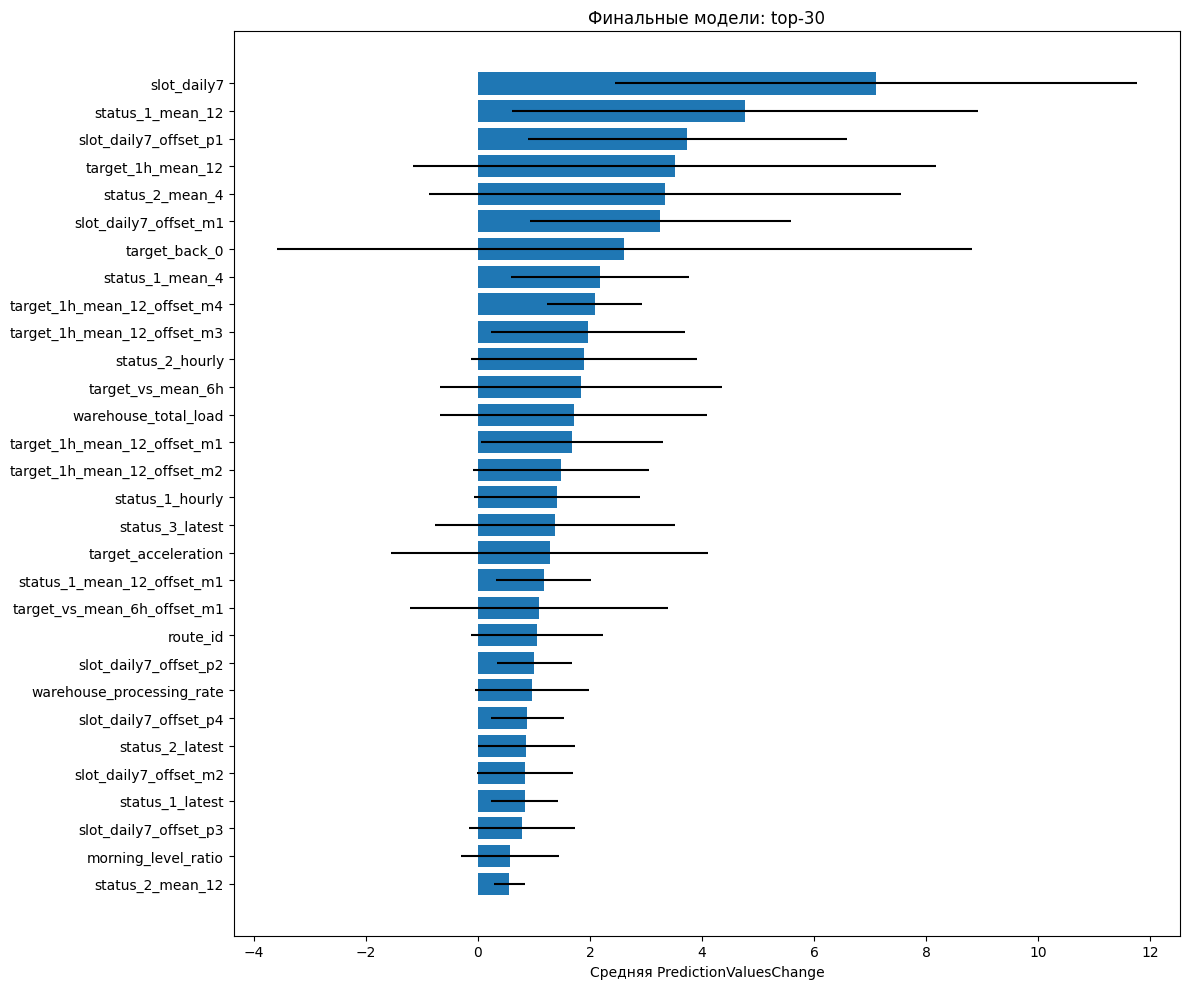

In [13]:
import matplotlib.pyplot as plt
builtin_importance = pd.concat(builtin_importance_parts, ignore_index=True)
builtin_importance.to_csv(IMPORTANCE_DIR / 'catboost_importance_by_horizon.csv', index=False)
importance_summary = builtin_importance.groupby(['stage', 'feature']).importance.agg(['mean', 'std']).reset_index().sort_values(['stage', 'mean'], ascending=[True, False])
importance_summary.to_csv(IMPORTANCE_DIR / 'catboost_importance_summary.csv', index=False)
display(importance_summary.groupby('stage', sort=False).head(30))
importance_by_horizon = builtin_importance.query("stage == 'final_model'").pivot(index='feature', columns='horizon', values='importance')
importance_by_horizon = importance_by_horizon.loc[importance_by_horizon.mean(axis=1).sort_values(ascending=False).index]
display(importance_by_horizon.head(30))
top = importance_summary.query("stage == 'final_model'").head(30).sort_values('mean')
fig, ax = plt.subplots(figsize=(12, 10))
ax.barh(top.feature, top['mean'], xerr=top['std'].fillna(0))
ax.set(xlabel='Средняя PredictionValuesChange', title='Финальные модели: top-30')
fig.tight_layout()
fig.savefig(IMPORTANCE_DIR / 'catboost_top30.png', dpi=150, bbox_inches='tight')
plt.show()


## Блочная permutation importance на test моделями до refit
Используются сохранённые оценочные модели и исходный train-словарь лагов. По умолчанию 7 дат test, все маршруты, 3 повтора, top-10 признаков, центральный корреляционный сигнал и его лаг, а также группы новых признаков и окон. Весь сезонный блок переставляется вместе, чтобы увидеть зависимость при взаимозаменяемых соседях.

Переставляются маршрутные траектории с циклическим сдвигом дат. Один индекс применяется к группе и всем горизонтам. Положительное изменение среднего дневного WAPE + |bias| означает ухудшение. horizon=0 объединяет все маршруты и горизонты дня. Это диагностика чистого CatBoost, без смеси и калибровки, без нового обучения или отбора. После использования test-важностей для нового подбора потребуется новая внешняя проверка.


Permutation importance: feature / slot_daily7
Permutation importance: feature / status_1_mean_12
Permutation importance: feature / target_1h_mean_12
Permutation importance: feature / slot_daily7_offset_p1
Permutation importance: feature / slot_daily7_offset_m1
Permutation importance: feature / status_2_mean_4
Permutation importance: feature / target_back_0
Permutation importance: feature / status_1_mean_4
Permutation importance: feature / target_1h_mean_12_offset_m3
Permutation importance: feature / status_2_hourly
Permutation importance: feature / lagged_status6_signal
Permutation importance: feature / selected_status6_lag_steps
Permutation importance: group / calendar
Permutation importance: group / local_statuses
Permutation importance: group / hub_combinations
Permutation importance: group / historical_lags
Permutation importance: group / target_change
Permutation importance: group / correlation_lag
Permutation importance: group / seasonal_windows
Permutation importance: group / re

,kind,name,horizon,delta_mean_daily_score_mean,delta_mean_daily_score_std,delta_pooled_score_mean,delta_pooled_score_std,delta_wape_mean,delta_wape_std,delta_abs_bias_mean,delta_abs_bias_std
189,group,seasonal_windows,0,0.048220,0.001535,0.048237,0.001546,0.046392,0.001014,0.001844,0.000532
144,group,local_statuses,0,0.018068,0.000382,0.018154,0.000336,0.016904,0.000171,0.001249,0.000251
99,feature,target_back_0,0,0.012610,0.000227,0.012620,0.000225,0.019002,0.000336,-0.006382,0.000126
171,group,recent_target,0,0.011312,0.000282,0.011324,0.000282,0.017947,0.000353,-0.006623,0.000084
162,group,recent_statuses,0,0.010098,0.000425,0.010120,0.000425,0.007274,0.000337,0.002846,0.000091
18,feature,slot_daily7,0,0.009210,0.000511,0.009226,0.000512,0.009223,0.000225,0.000002,0.000298
72,feature,status_2_mean_4,0,0.009123,0.000172,0.009141,0.000169,0.007544,0.000136,0.001596,0.000033
63,feature,status_2_hourly,0,0.005287,0.000205,0.005302,0.000203,0.003665,0.000132,0.001637,0.000115
126,group,historical_lags,0,0.005036,0.000108,0.005037,0.000107,0.001402,0.000140,0.003635,0.000105
198,group,target_change,0,0.004579,0.000080,0.004572,0.000076,0.006736,0.000078,-0.002163,0.000024


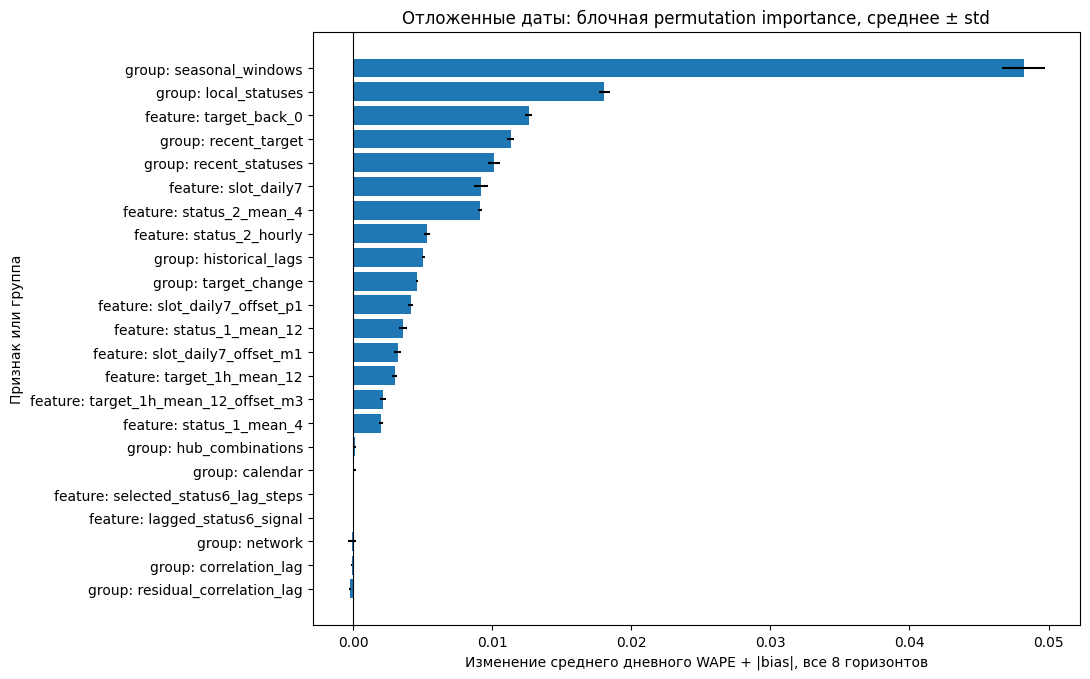

horizon,1,2,3,4,5,6,7,8,mean_all_8
feature,,,,,,,,,
slot_daily7,1.641280,2.624068,3.687720,6.394056,9.275463,6.545845,11.508516,15.187506,7.108057
status_1_mean_12,0.019651,0.174618,0.834230,3.564198,7.715781,10.851204,7.526799,7.451616,4.767262
slot_daily7_offset_p1,0.156552,1.582783,1.911701,3.585165,2.742989,5.754944,9.154650,5.007185,3.736996
target_1h_mean_12,0.035294,0.049138,0.127398,0.468185,0.704481,6.286879,9.229853,11.223237,3.515558
status_2_mean_4,1.457971,12.962339,4.712617,3.645471,2.746118,0.518709,0.520096,0.144166,3.338436
...,...,...,...,...,...,...,...,...,...
slot_days_back_1_offset_m3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.052265,0.006533
status_5_mean_12_offset_m2,0.001897,0.002903,0.011160,0.021169,0.014270,0.000000,0.000000,0.000000,0.006425
status_5_mean_4_offset_m1,0.011124,0.014472,0.011137,0.000000,0.014440,0.000000,0.000000,0.000000,0.006397


In [14]:
def block_permutation_index(frame, seed):
    rng = np.random.default_rng(seed)
    days = pd.DatetimeIndex(frame.cutoff.unique()).sort_values()
    route_values = np.sort(frame.route_id.unique())
    keys = pd.MultiIndex.from_frame(frame[['cutoff', 'route_id']])
    if not keys.is_unique or len(frame) != len(days) * len(route_values):
        raise ValueError('Permutation importance требует полную панель дата × маршрут')
    date_shift = int(rng.integers(1, len(days))) if len(days) > 1 else 0
    donor_days = days[np.roll(np.arange(len(days)), date_shift)][days.get_indexer(frame.cutoff)]
    donor_routes = rng.permutation(route_values)[pd.Index(route_values).get_indexer(frame.route_id)]
    donor = keys.get_indexer(pd.MultiIndex.from_arrays([donor_days, donor_routes]))
    if (donor < 0).any() or len(np.unique(donor)) != len(frame):
        raise ValueError('Перестановка не является биекцией')
    return donor

def permutation_deltas(meta_parts, original_parts, shuffled_parts):
    rows = []
    for h, meta, original, shuffled in zip(range(1, 9), meta_parts, original_parts, shuffled_parts):
        before, after = (score_row(meta, original, 'baseline'), score_row(meta, shuffled, 'permuted'))
        rows.append({'horizon': h, 'delta_mean_daily_score': after['среднее по дням'] - before['среднее по дням'], 'delta_pooled_score': after['метрика конкурса'] - before['метрика конкурса'], 'delta_wape': after['WAPE'] - before['WAPE'], 'delta_abs_bias': after['|Relative Bias|'] - before['|Relative Bias|']})
    combined = pd.concat(meta_parts, ignore_index=True)
    before = score_row(combined, np.concatenate(original_parts), 'baseline')
    after = score_row(combined, np.concatenate(shuffled_parts), 'permuted')
    rows.append({'horizon': 0, 'delta_mean_daily_score': after['среднее по дням'] - before['среднее по дням'], 'delta_pooled_score': after['метрика конкурса'] - before['метрика конкурса'], 'delta_wape': after['WAPE'] - before['WAPE'], 'delta_abs_bias': after['|Relative Bias|'] - before['|Relative Bias|']})
    return rows

def run_permutation_importance():
    if PERMUTATION_MAX_DAYS < 2 or PERMUTATION_REPEATS < 2 or PERMUTATION_TOP_N < 1:
        raise ValueError('Для диагностики нужны >=2 даты, >=2 повтора и положительный top-N')
    available_days = dates[dates >= holdout_start]
    pick = np.unique(np.linspace(0, len(available_days) - 1, min(PERMUTATION_MAX_DAYS, len(available_days))).round().astype(int))
    selected_days = available_days[pick]
    models, matrices, metadata, original = ([], [], [], [])
    baseline_rows = []
    for h in range(1, 9):
        model = CatBoostRegressor()
        model.load_model(str(MODEL_DIR / f'catboost_h{h}_validation.cbm'))
        names = model.feature_names_
        read_columns = list(dict.fromkeys(['cutoff', 'timestamp', 'route_id', 'y', *names]))
        frame = pd.read_parquet(OUT / f'history_h{h}.parquet', columns=read_columns, filters=[('cutoff', 'in', selected_days.to_pydatetime().tolist())])
        frame = frame.sort_values(['cutoff', 'route_id']).reset_index(drop=True)
        if len(frame) != len(selected_days) * len(routes):
            raise ValueError('Неполная панель отложенных данных для важностей')
        meta = frame[['cutoff', 'timestamp', 'route_id', 'y']].copy()
        matrix = frame[names].copy()
        prediction = (model.predict(matrix) * TARGET_SCALE).clip(min=0)
        baseline_rows.append({'horizon': h, **score_row(meta, prediction, 'permutation_baseline')})
        models.append(model)
        matrices.append(matrix)
        metadata.append(meta)
        original.append(prediction)
    combined = pd.concat(metadata, ignore_index=True)
    baseline_rows.append({'horizon': 0, **score_row(combined, np.concatenate(original), 'permutation_baseline')})
    pd.DataFrame(baseline_rows).to_csv(IMPORTANCE_DIR / 'permutation_baseline.csv', index=False)
    rank = builtin_importance.query("stage == 'validation_model'").groupby('feature').importance.mean().sort_values(ascending=False)
    individual = list(dict.fromkeys([*rank.head(PERMUTATION_TOP_N).index, 'lagged_status6_signal', 'selected_status6_lag_steps']))
    available_columns = set().union(*(set(matrix.columns) for matrix in matrices))
    specs = [('feature', name, [name]) for name in individual if name in available_columns]
    specs += [('group', name, [c for c in names if c in available_columns]) for name, names in FEATURE_GROUPS.items()]
    specs = [spec for spec in specs if spec[2]]
    (IMPORTANCE_DIR / 'permutation_settings.json').write_text(json.dumps({'days': [str(d) for d in selected_days], 'routes': len(routes), 'repeats': PERMUTATION_REPEATS, 'seed': 42, 'model_stage': 'validation_model', 'lag_fit_before': str(LAG_VALIDATION_FIT_BEFORE), 'specs': [{'kind': kind, 'name': name, 'columns': columns} for kind, name, columns in specs]}, ensure_ascii=False, indent=2))
    rows = []
    for kind, name, columns in specs:
        for repeat in range(PERMUTATION_REPEATS):
            shuffled = []
            for model, matrix, meta in zip(models, matrices, metadata):
                donor = block_permutation_index(meta, seed=42 + repeat)
                permuted = matrix.copy()
                active_columns = [column for column in columns if column in matrix.columns]
                permuted.loc[:, active_columns] = matrix.iloc[donor][active_columns].to_numpy()
                shuffled.append((model.predict(permuted) * TARGET_SCALE).clip(min=0))
            for row in permutation_deltas(metadata, original, shuffled):
                rows.append({'kind': kind, 'name': name, 'repeat': repeat, 'n_features': len(columns), **row})
        print(f'Permutation importance: {kind} / {name}')
    detail = pd.DataFrame(rows)
    detail.to_csv(IMPORTANCE_DIR / 'permutation_detail.csv', index=False)
    metrics = ['delta_mean_daily_score', 'delta_pooled_score', 'delta_wape', 'delta_abs_bias']
    summary = detail.groupby(['kind', 'name', 'horizon'])[metrics].agg(['mean', 'std'])
    summary.columns = ['_'.join(column) for column in summary.columns]
    summary = summary.reset_index().sort_values('delta_mean_daily_score_mean', ascending=False)
    summary.to_csv(IMPORTANCE_DIR / 'permutation_summary.csv', index=False)
    return summary
if PERMUTATION_ENABLED:
    permutation_summary = run_permutation_importance()
    overall = permutation_summary.loc[permutation_summary.horizon.eq(0)].copy()
    display(overall)
    plot = overall.sort_values('delta_mean_daily_score_mean')
    fig, ax = plt.subplots(figsize=(11, max(5, len(plot) * 0.3)))
    ax.barh(plot.kind + ': ' + plot.name, plot.delta_mean_daily_score_mean, xerr=plot.delta_mean_daily_score_std.fillna(0))
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set(xlabel='Изменение среднего дневного WAPE + |bias|, все 8 горизонтов', ylabel='Признак или группа', title='Отложенные даты: блочная permutation importance, среднее ± std')
    fig.tight_layout()
    fig.savefig(IMPORTANCE_DIR / 'permutation_importance.png', dpi=150, bbox_inches='tight')
    plt.show()
else:
    print('Permutation importance отключена настройкой PERMUTATION_ENABLED; важности CatBoost показаны выше.')

importance_final_table = importance_by_horizon.copy()
importance_final_table['mean_all_8'] = importance_final_table.fillna(0).sum(axis=1)/8
importance_final_table = importance_final_table.sort_values('mean_all_8',ascending=False)
importance_final_table.to_csv(IMPORTANCE_DIR/'final_feature_importance_table.csv')
display(importance_final_table)
